# Lekcja 3. Iloczyn skalarny, inne bazy i faza

**Cel:** zobaczyć, że pomiar można robić w dowolnej bazie, i zrozumieć, dlaczego faza globalna nic nie znaczy, a faza względna znaczy bardzo dużo.

## 1. Słownik: notacja fizyków a algebra liniowa

Napis w kecie to **indeks wektora bazy standardowej, zapisany dwójkowo**. Kety bazowe to kodowanie *one-hot*: liczba w kecie to pozycja jedynki, licząc od zera.

| Notacja Diraca | Algebra liniowa |
|---|---|
| $\lvert\psi\rangle$ | wektor kolumnowy $v \in \mathbb{C}^n$ |
| $\langle\psi\rvert$ | $v^{*}$ (sprzężony i transponowany) |
| $\langle\varphi\vert\psi\rangle$ | iloczyn skalarny $\langle u, v\rangle = u^{*}v$ |
| $\lvert\psi\rangle\langle\psi\rvert$ | macierz $v v^{*}$ (rzut na $v$) |
| $\lvert 0\rangle$, $\lvert 1\rangle$ | $e_0 = (1, 0)$, $e_1 = (0, 1)$ |
| $\lvert ab\rangle = \lvert a\rangle \otimes \lvert b\rangle$ | $e_a \otimes e_b = e_{2a+b}$ (iloczyn Kroneckera) |
| $U\lvert\psi\rangle$ | $Uv$ |

Przykłady: $|10\rangle$ to $10_2 = 2$, czyli $e_2 = (0, 0, 1, 0)$; $|101\rangle$ to $e_5 \in \mathbb{C}^8$.

Iloczyn skalarny jest liniowy w drugim argumencie: $\langle u, v\rangle = \sum_k \overline{u_k} v_k$. Sprzężenie jest konieczne, żeby norma była rzeczywista i nieujemna: bez niego wektor $(1, i)$ miałby „długość” $1 + i^2 = 0$.

## 2. Reguła Borna w dowolnej bazie

Dla bazy ortonormalnej $\{u, w\}$:

$$P(u) = |\langle u, v\rangle|^2, \qquad P(w) = |\langle w, v\rangle|^2,$$

a po pomiarze stan to $u$ albo $w$. Pomiar w bazie $\{e_0, e_1\}$ to szczególny przypadek: $\langle e_0, v\rangle = \alpha$.

Najważniejsza baza poza obliczeniową:

$$u_+ = \tfrac{1}{\sqrt{2}}(e_0 + e_1) \;\; (\text{etykieta } |+\rangle), \qquad u_- = \tfrac{1}{\sqrt{2}}(e_0 - e_1) \;\; (\text{etykieta } |-\rangle).$$

Sprzęt mierzy tylko w $\{e_0, e_1\}$. Pomiar w innej bazie robi się, obracając stan bramką przed pomiarem (lekcja 5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # etykieta |0⟩
e1 = np.array([0, 1], dtype=complex)   # etykieta |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Wypisz wektor stanu z etykietami bitów (etykieta = pozycja w zapisie dwójkowym)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  pozycja {k} ({format(k, f'0{n}b')}): amplituda {np.round(a, 3)}, P = {abs(a)**2:.3f}")

up = (e0 + e1) / np.sqrt(2)   # |+⟩
um = (e0 - e1) / np.sqrt(2)   # |-⟩
ip = lambda u, v: np.vdot(u, v)   # iloczyn skalarny <u, v> = u* v

print("<u+, u+> =", round(ip(up, up).real, 3), "  <u-, u-> =", round(ip(um, um).real, 3), "  <u+, u-> =", round(abs(ip(up, um)), 3))

def P_baza(v, baza):
    return [abs(ip(u, v)) ** 2 for u in baza]

for nazwa, v in {"e0": e0, "u+": up, "u-": um}.items():
    print(f"{nazwa}:  baza z: P = {np.round(P_baza(v, [e0, e1]), 3)}   baza x: P = {np.round(P_baza(v, [up, um]), 3)}")

<u+, u+> = 1.0   <u-, u-> = 1.0   <u+, u-> = 0.0
e0:  baza z: P = [1. 0.]   baza x: P = [0.5 0.5]
u+:  baza z: P = [0.5 0.5]   baza x: P = [1. 0.]
u-:  baza z: P = [0.5 0.5]   baza x: P = [0. 1.]

## 3. Faza globalna nie ma znaczenia

Dla dowolnej bazy i dowolnego $\gamma$:

$$|\langle u, e^{i\gamma} v\rangle|^2 = |e^{i\gamma}|^2\, |\langle u, v\rangle|^2 = |\langle u, v\rangle|^2.$$

Żaden pomiar w żadnej bazie nie odróżni $v$ od $e^{i\gamma} v$. To wynika po prostu z tego, że $|e^{i\gamma}| = 1$. Na przykład $e_0$ i $-e_0$ to ten sam stan.

## 4. Faza względna

Zapisz amplitudy biegunowo: $\alpha = |\alpha| e^{i\varphi_\alpha}$, $\beta = |\beta| e^{i\varphi_\beta}$. Wtedy

$$v = e^{i\varphi_\alpha}\big(|\alpha|\, e_0 + |\beta|\, e^{i(\varphi_\beta - \varphi_\alpha)}\, e_1\big).$$

Czynnik przed nawiasem to faza globalna, którą wyrzucamy. Zostaje

$$\varphi = \varphi_\beta - \varphi_\alpha,$$

czyli **faza względna**: kąt między liczbami $\alpha$ i $\beta$ na płaszczyźnie zespolonej.

> **To było trudne:** faza względna nie mówi, jak mają się do siebie wektory bazy (te są zawsze ortogonalne). Mówi, jak mają się do siebie **współrzędne** stanu. Między częścią przy $e_0$ a częścią przy $e_1$ są dwie relacje: **ile** jest każdej (stosunek $|\alpha| : |\beta|$) i **jak bardzo są przesunięte w fazie** ($\varphi$). Faza względna, jak same współrzędne, zależy od wybranej bazy.

Przykłady (wszystkie z $|\alpha| = |\beta| = 1/\sqrt{2}$): $\varphi = 0$ daje $u_+$, $\varphi = \pi$ daje $u_-$, $\varphi = \pi/2$ daje $(e_0 + i e_1)/\sqrt{2}$ (etykieta $|{+i}\rangle$).

## 5. Skąd cosinus: wyprowadzenie krok po kroku

Pomiar w bazie $\{u_+, u_-\}$:

1. $u_+^{*} = \tfrac{1}{\sqrt{2}}(1, 1)$ (współczynniki rzeczywiste, sprzężenie nic nie zmienia).
2. $\langle u_+, v\rangle = \tfrac{1}{\sqrt{2}}(\alpha + \beta)$.
3. $P(+) = \tfrac{1}{2}|\alpha + \beta|^2$.
4. $|\alpha + \beta|^2 = (\alpha + \beta)(\bar\alpha + \bar\beta) = |\alpha|^2 + |\beta|^2 + \alpha\bar\beta + \bar\alpha\beta$.
5. $\alpha\bar\beta + \bar\alpha\beta = 2\,\mathrm{Re}(\bar\alpha\beta)$, bo to liczba plus jej sprzężenie.
6. $\bar\alpha\beta = |\alpha||\beta|\, e^{i(\varphi_\beta - \varphi_\alpha)} = |\alpha||\beta|\, e^{i\varphi}$: sprzężenie „odejmuje” fazę $\alpha$, zostaje różnica faz.
7. $\mathrm{Re}(e^{i\varphi}) = \cos\varphi$ (wzór Eulera).
8. Razem:

$$P(+) = \tfrac{1}{2}\big(1 + 2|\alpha||\beta|\cos\varphi\big).$$

To **twierdzenie cosinusów** dla sumy dwóch wektorów na płaszczyźnie o długościach $|\alpha|, |\beta|$ pod kątem $\varphi$. Wyraz $2|\alpha||\beta|\cos\varphi$ to **interferencja**: pojawia się tylko wtedy, gdy amplitudy dodajemy **przed** wzięciem modułu. Pomiar w $\{e_0, e_1\}$ bierze moduł każdej amplitudy osobno, więc fazy względnej nie widzi.

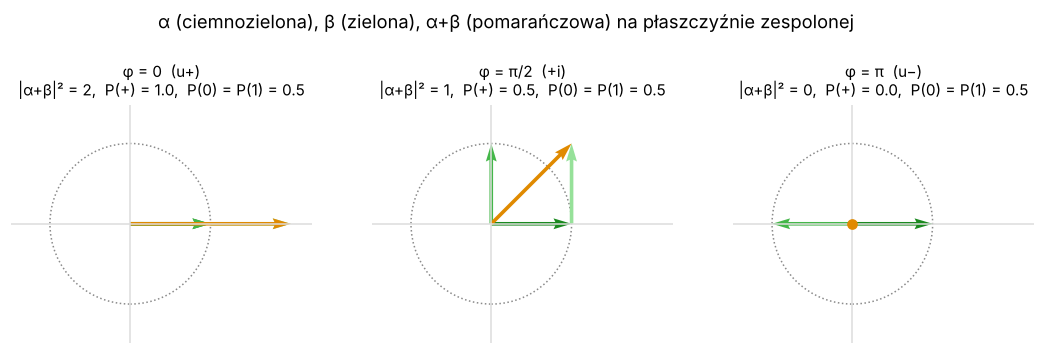

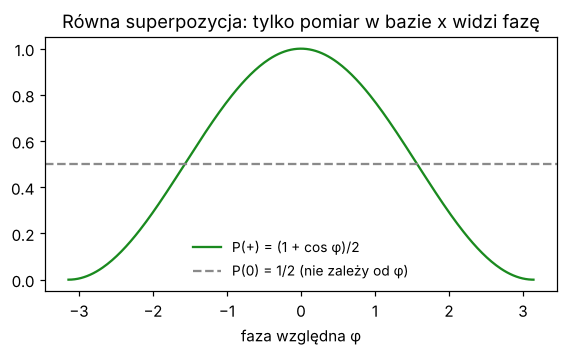

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
a = 1 / np.sqrt(2)
for ax, phi, tytul in zip(axs, [0, np.pi / 2, np.pi], ["φ = 0  (u+)", "φ = π/2  (+i)", "φ = π  (u−)"]):
    b = a * np.exp(1j * phi); s = a + b
    ax.add_patch(plt.Circle((0, 0), a, fill=False, ls=":", color=GREY))
    ax.axhline(0, color="#DDD", lw=1); ax.axvline(0, color="#DDD", lw=1)
    kw = dict(angles="xy", scale_units="xy", scale=1, width=0.012)
    ax.quiver(0, 0, a, 0, color=DARK, **kw)
    ax.quiver(0, 0, b.real, b.imag, color=GREEN, **kw)
    if abs(s) > 1e-9:
        ax.quiver(a, 0, b.real, b.imag, color=LIGHT, **kw)
        ax.quiver(0, 0, s.real, s.imag, color=ORANGE, **kw)
    else:
        ax.plot(0, 0, "o", color=ORANGE)
    ax.set_title(f"{tytul}\n|α+β|² = {abs(s)**2:.0f},  P(+) = {abs(s)**2/2:.1f},  P(0) = P(1) = 0.5", fontsize=10)
    ax.set_xlim(-1.05, 1.6); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("α (ciemnozielona), β (zielona), α+β (pomarańczowa) na płaszczyźnie zespolonej")

phi = np.linspace(-np.pi, np.pi, 300)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(phi, (1 + np.cos(phi)) / 2, color=DARK, label="P(+) = (1 + cos φ)/2")
ax.axhline(0.5, color=GREY, ls="--", label="P(0) = 1/2 (nie zależy od φ)")
ax.set_xlabel("faza względna φ"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Równa superpozycja: tylko pomiar w bazie x widzi fazę")

## 6. Superpozycja to nie „ukryte 0 albo 1”

Porównaj dwa przypadki:

- **A:** układ w stanie $u_+$;
- **B:** „klasyczna moneta”: układ jest naprawdę w $e_0$ albo w $e_1$, każde z prawdopodobieństwem 1/2, tylko nie wiemy w którym.

W bazie $\{e_0, e_1\}$ oba dają 50/50. W bazie $\{u_+, u_-\}$:

- A daje „+” w 100% przypadków, bo $u_+$ jest wektorem tej bazy;
- B daje „+” w 50% przypadków, bo $|\langle u_+, e_0\rangle|^2 = |\langle u_+, e_1\rangle|^2 = 1/2$.

To da się zmierzyć, a eksperymenty widzą A. Superpozycja to inny stan niż każda mieszanka zer i jedynek.

In [3]:
N = 10_000
rng = np.random.default_rng(1)

# A: zawsze ten sam stan u+
wyniki_A = rng.choice(["+", "-"], size=N, p=P_baza(up, [up, um]))

# B: losowo e0 albo e1 ("klasyczna moneta"), potem pomiar w bazie x
stany_B = rng.choice([0, 1], size=N)
wyniki_B = np.array([rng.choice(["+", "-"], p=P_baza([e0, e1][s], [up, um])) for s in stany_B])

for nazwa, w in (("A: u+", wyniki_A), ("B: moneta e0/e1", wyniki_B)):
    print(f"{nazwa:>16}: w bazie x wynik '+' w {np.mean(w == '+'):.1%} przypadków")

           A: u+: w bazie x wynik '+' w 100.0% przypadków
 B: moneta e0/e1: w bazie x wynik '+' w 50.1% przypadków

## Podsumowanie

> Pomiar można wykonać w dowolnej bazie ortonormalnej: $P(u) = |\langle u, v\rangle|^2$. Faza globalna nie ma żadnego znaczenia, bo $|e^{i\gamma}| = 1$. Faza względna $\varphi$ to kąt między $\alpha$ a $\beta$ na płaszczyźnie zespolonej. Nie zmienia $P(0)$ i $P(1)$, ale decyduje, czy amplitudy wzmocnią się, czy wygaszą, kiedy pomiar je nakłada: $P(+) = \tfrac12(1 + 2|\alpha||\beta|\cos\varphi)$.

## Zadania

1. Zapisz $e_1$ w bazie $\{u_+, u_-\}$.
2. Stan $(3/5, 4/5)$. Policz $P(+)$ i $P(-)$.
3. Czy stany $(e_0 + i e_1)/\sqrt{2}$ i $(e_0 - i e_1)/\sqrt{2}$ da się odróżnić pomiarem w bazie $\{e_0, e_1\}$? A w bazie $\{u_+, u_-\}$? (Wskazówka: dla $\varphi = \pm\pi/2$ wzór daje to samo $P(+)$. Rozwiązanie tej zagadki jest w lekcji 4.)
4. Stan $u_+$ ma w bazie $\{e_0, e_1\}$ współrzędne $(1/\sqrt2, 1/\sqrt2)$. Jakie ma współrzędne w bazie $\{u_+, u_-\}$? Co to mówi o „byciu w superpozycji”?